In [32]:
#PRACTICA 1 TAA, REALIZADO POR ÁNGEL ANTOLÍN CARAMAZANA

import pandas as pd
import numpy as np
from scipy.stats import entropy
import matplotlib.pyplot as plt

In [33]:
#1. CARGAR ARCHIVO
weather = pd.read_csv('./weather.nominal.csv')
weather

,outlook,temperature,humidity,windy,play
0,sunny,hot,high,False,no
1,sunny,hot,high,True,no
2,overcast,hot,high,False,yes
3,rainy,mild,high,False,yes
4,rainy,cool,normal,False,yes
5,rainy,cool,normal,True,no
6,overcast,cool,normal,True,yes
7,sunny,mild,high,False,no
8,sunny,cool,normal,False,yes
9,rainy,mild,normal,False,yes


In [34]:
atributos = ['outlook', 'temperature', 'humidity', 'windy']
objetivo = 'play'

In [35]:
np.array(weather['outlook'].value_counts(normalize= True))


array([0.35714286, 0.35714286, 0.28571429])

In [36]:
# 2. CÁLCULO DE MÉTRICAS "AISLADAS"
probabilidad = {}
for columna in weather.columns:
    probabilidad[columna] = np.array(weather[columna].value_counts(normalize = True))


dict_entropia_aislada = {}
dict_gini_aislado = {}

for columna, probs in probabilidad.items():

    #Calcular entropia de cada probabilidad usando la funcion ya implementada
    dict_entropia_aislada[columna] = entropy(probs, base = 2)

    # Calcular GINI manualmente de cada probabilidad (1-sumatorio prob²)
    dict_gini_aislado[columna] = 1 - np.sum(probs**2)



In [37]:
probabilidad

{'outlook': array([0.35714286, 0.35714286, 0.28571429]),
 'temperature': array([0.42857143, 0.28571429, 0.28571429]),
 'humidity': array([0.5, 0.5]),
 'windy': array([0.57142857, 0.42857143]),
 'play': array([0.64285714, 0.35714286])}

In [38]:
dict_entropia_aislada

{'outlook': np.float64(1.5774062828523452),
 'temperature': np.float64(1.556656707462823),
 'humidity': np.float64(1.0),
 'windy': np.float64(0.9852281360342515),
 'play': np.float64(0.940285958670631)}

In [39]:
dict_gini_aislado

{'outlook': np.float64(0.6632653061224489),
 'temperature': np.float64(0.653061224489796),
 'humidity': np.float64(0.5),
 'windy': np.float64(0.48979591836734704),
 'play': np.float64(0.4591836734693877)}

In [40]:
# 3. FUNCIÓN PARA GANANCIA DE INFORMACIÓN (MANUAL)
def calcular_ganancia(datos, atributo, objetivo, metodo):
    probs_padre = datos[objetivo].value_counts(normalize=True)
    
    if metodo == 'entropia':
        metrica_padre = entropy(probs_padre, base=2)
    else: 
        metrica_padre = 1 - np.sum(probs_padre**2)
    
    metrica_hijos = 0
    for valor in datos[atributo].unique():
        
        #Creo un subgrupo que es una tablita con solo las instancias de cada atributo, es decir cuando Atributo = Overlook, pues una para 
        # Sunny, otra para Rain, etc y luego lo divides entre el numero total de instancias para sacar el peso
        subgrupo = datos[datos[atributo] == valor]
        peso = len(subgrupo) / len(datos)
        
        probs_hijo = subgrupo[objetivo].value_counts(normalize=True)
        
        if metodo == 'entropia':
            val = entropy(probs_hijo, base=2)
        else:
            val = 1 - np.sum(probs_hijo**2)
            
        metrica_hijos += peso * val
        
    return metrica_padre - metrica_hijos


dict_ganancia_entropia = {}
dict_ganancia_gini = {}

for atributo in atributos:
    dict_ganancia_entropia[atributo] = calcular_ganancia(weather, atributo, objetivo, 'entropia')
    dict_ganancia_gini[atributo] = calcular_ganancia(weather, atributo, objetivo, 'gini')


In [41]:
dict_ganancia_entropia

{'outlook': np.float64(0.246749819774439),
 'temperature': np.float64(0.029222565658954758),
 'humidity': np.float64(0.15183550136234159),
 'windy': np.float64(0.04812703040826938)}

In [42]:
dict_ganancia_gini

{'outlook': np.float64(0.11632653061224485),
 'temperature': np.float64(0.018707482993197244),
 'humidity': np.float64(0.09183673469387743),
 'windy': np.float64(0.030612244897959162)}

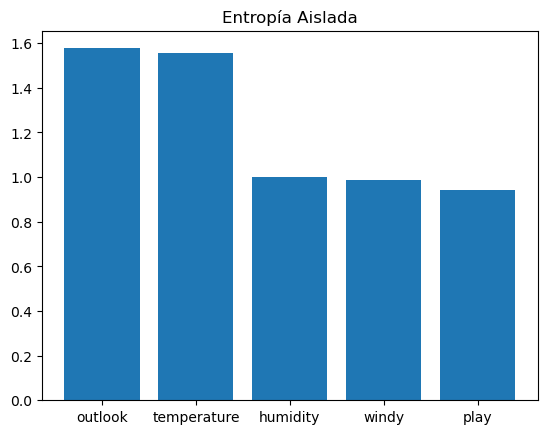

In [43]:
#5. REPRESENTACION

plt.figure()

plt.bar(dict_entropia_aislada.keys(), dict_entropia_aislada.values())
plt.title('Entropía Aislada')
plt.show()

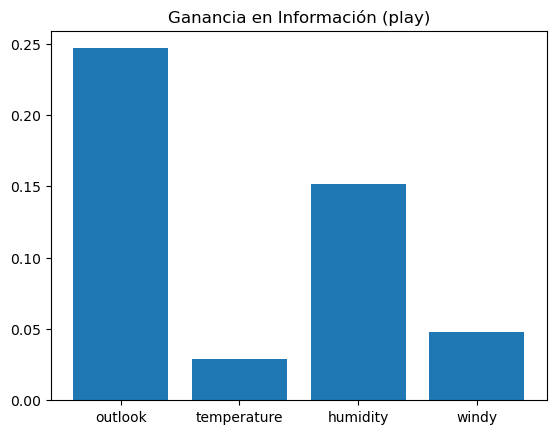

In [44]:
plt.figure()

plt.bar(dict_ganancia_entropia.keys(), dict_ganancia_entropia.values())
plt.title('Ganancia en Información (play)')
plt.show()

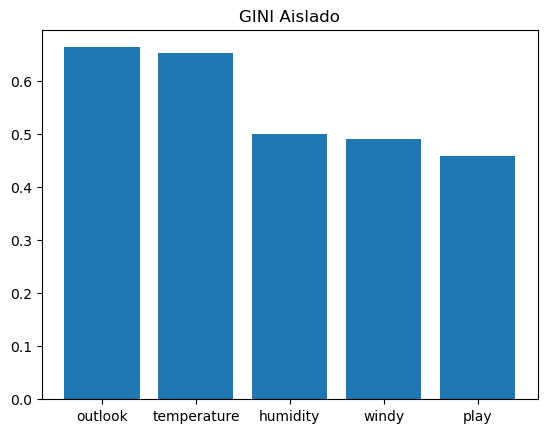

In [45]:
plt.figure()

plt.bar(dict_gini_aislado.keys(), dict_gini_aislado.values())
plt.title('GINI Aislado')
plt.show()

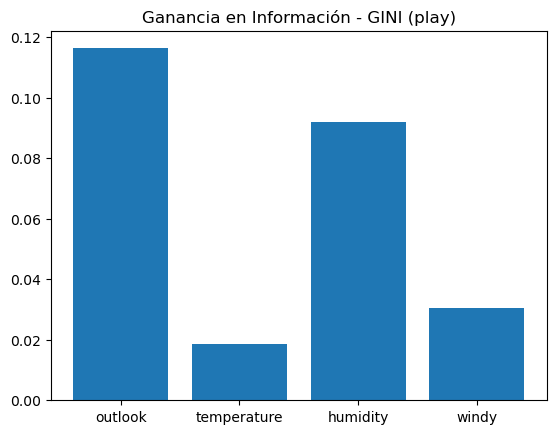

In [46]:
plt.figure()

plt.bar(dict_ganancia_gini.keys(), dict_ganancia_gini.values())
plt.title('Ganancia en Información - GINI (play)')
plt.show()

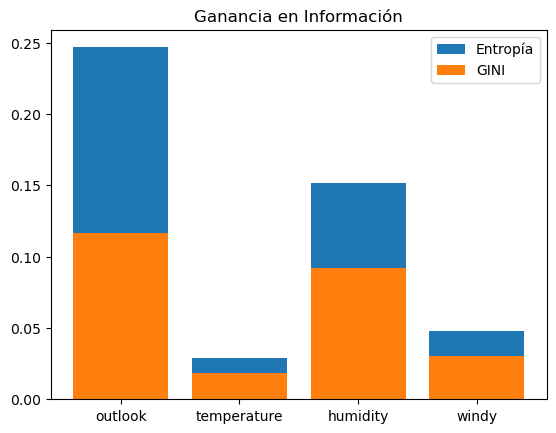

In [47]:
plt.figure()

plt.bar(dict_ganancia_entropia.keys(), dict_ganancia_entropia.values(), label = 'Entropía')

plt.bar(dict_ganancia_gini.keys(), dict_ganancia_gini.values(), label = 'GINI')

plt.title('Ganancia en Información')

plt.legend()

plt.show()